# Futures Term Structure (Contango vs. Backwardation)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Plots futures prices against time to expiry for several dates, alongside the history of the spread between a later contract and the front month. Upward-sloping curves (contango) mean later delivery costs more, usually because of storage and financing. Downward-sloping curves (backwardation) signal scarcity today. The slope drives the roll return of every futures-based investment.

## When to use

- Explain roll yield and why commodity ETFs can lag spot prices
- Show how supply shocks flip a market from contango to backwardation
- Compare curve shapes across commodities, VIX futures or rates futures

## Avoid when

- Readers only need the spot price trend
- Contracts have very different liquidity (thin back months distort the curve)

## Alternatives

- Yield curve chart (the same idea for bonds)
- Calendar-spread line chart only

## Design tips

- Plot maturity in months on the x-axis, not calendar dates, so curves from different days align
- Use a polarity color for the spread (blue = contango, orange = backwardation)
- Mark the dates of the plotted curves on the spread history

## Example

Simulated crude-oil futures, 2019–2024: futures priced as F = S·e^((r − y)·T) with a stochastic convenience yield y. The market sits in contango during a glut and flips into steep backwardation during a supply squeeze. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(12)
dates = pd.bdate_range("2019-01-01", "2024-12-31")
n = len(dates)
t = np.arange(n)
spot = 60 * np.exp(np.cumsum(rng.normal(0, 0.022, n)) * 0.6 + 0.25 * np.sin(t / 260))
# convenience yield: low in a glut (2020), high in a squeeze (2022), mean-reverting noise
conv = 0.04 + 0.10 * np.exp(-((t - 330) / 60.0) ** 2) * -1.2 + 0.16 * np.exp(-((t - 900) / 120.0) ** 2)
conv = conv + np.convolve(rng.normal(0, 0.01, n), np.ones(20) / 20, mode="same")
r = 0.03
months = np.arange(1, 13)
curves = pd.DataFrame(spot[:, None] * np.exp((r - conv[:, None]) * months[None, :] / 12),
                      index=dates, columns=[f"M{m}" for m in months])
spread = (curves["M12"] / curves["M1"] - 1).rename("12M − 1M spread")
show_dates = [pd.Timestamp(d) for d in ("2019-06-03", "2020-04-20", "2022-06-14", "2024-06-03")]
curves.loc[curves.index.isin(show_dates)].round(1)

,M1,M2,M3,M4,M5,M6,M7,M8,M9,M10,M11,M12
2019-06-03,67.6,67.5,67.5,67.4,67.3,67.3,67.2,67.1,67.1,67.0,66.9,66.9
2020-04-20,91.9,92.7,93.6,94.4,95.2,96.1,97.0,97.8,98.7,99.6,100.5,101.4
2022-06-14,63.9,63.1,62.2,61.3,60.5,59.6,58.8,58.0,57.2,56.4,55.6,54.9
2024-06-03,72.1,72.1,72.0,71.9,71.9,71.8,71.8,71.7,71.7,71.6,71.6,71.5


### Plot

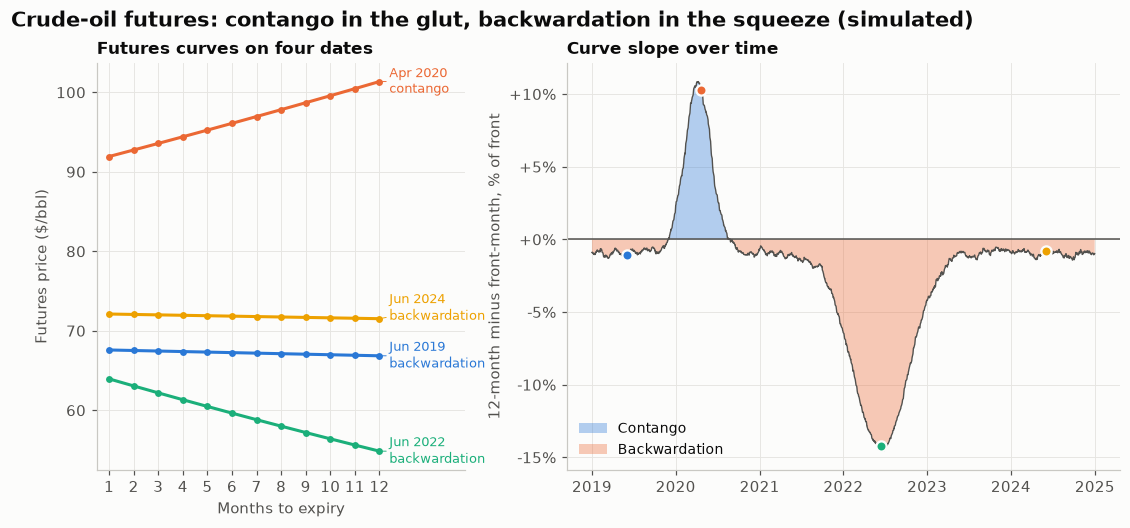

In [3]:
fig, (ax_c, ax_s) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.5], "wspace": 0.22})
ends, label_y = [], {}
for d in show_dates:
    d = curves.index[curves.index.get_indexer([d], method="nearest")[0]]
    ends.append((curves.loc[d].iloc[-1], d))
last = -np.inf
for v, d in sorted(ends):                       # keep end labels at least 6 $ apart
    label_y[d] = max(v, last + 6)
    last = label_y[d]
for k, d in enumerate(show_dates):
    d = curves.index[curves.index.get_indexer([d], method="nearest")[0]]
    row = curves.loc[d]
    ax_c.plot(months, row.values, color=PALETTE[k], marker="o", markersize=3.5)
    shape = "contango" if row.iloc[-1] > row.iloc[0] else "backwardation"
    ax_c.annotate(f"{d:%b %Y}\n{shape}", (months[-1], row.iloc[-1]), xytext=(12.4, label_y[d]),
                  textcoords="data", va="center", fontsize=8.5, color=PALETTE[k],
                  arrowprops=dict(arrowstyle="-", color=PALETTE[k], linewidth=0.6, shrinkA=0, shrinkB=2))
    ax_s.scatter(d, spread.loc[d], color=PALETTE[k], s=45, zorder=4, edgecolor="#fcfcfb", linewidth=1.5)
ax_c.set_xticks(months)
ax_c.set_xlim(0.5, 15.5)
ax_c.set_xlabel("Months to expiry")
ax_c.set_ylabel("Futures price ($/bbl)")
ax_c.set_title("Futures curves on four dates", fontsize=11)

ax_s.fill_between(spread.index, spread, 0, where=spread >= 0, color=PALETTE[0], alpha=0.35,
                  interpolate=True, linewidth=0, label="Contango")
ax_s.fill_between(spread.index, spread, 0, where=spread < 0, color=PALETTE[1], alpha=0.35,
                  interpolate=True, linewidth=0, label="Backwardation")
ax_s.plot(spread.index, spread, color="#52514e", linewidth=0.9)
ax_s.axhline(0, color="#52514e", linewidth=1)
ax_s.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax_s.set_ylabel("12-month minus front-month, % of front")
ax_s.set_title("Curve slope over time", fontsize=11)
ax_s.legend(loc="lower left", fontsize=9)
fig.suptitle("Crude-oil futures: contango in the glut, backwardation in the squeeze (simulated)",
             x=0.06, ha="left", fontsize=14, fontweight="bold")
plt.show()

## How to read it

Left: each line is the whole futures curve on one date. Rising lines are contango and falling lines are backwardation. Right: the 12-month minus front-month spread as a percentage of the front month, blue above zero (contango) and orange below. The dots mark the four dates drawn on the left.

---
Standalone script: [`futures_term_structure.py`](futures_term_structure.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)